# 1. Project scope and target definitions

## Primary research question

Which observable aviation accident factors are most strongly associated with aircraft damage severity?

## Secondary outcomes

This project also prepares binary classification targets for:

- Fatality: whether one or more fatalities were reported.
- Nonfatal injury: whether one or more nonfatal injuries were reported.

These targets describe associations in historical FAA records; they do not establish that a factor caused an accident.

## Target decisions

- Aircraft damage classification uses the `Minor`, `Substantial`, and `Destroyed` categories. Missing and `Unknown` damage values are excluded from that target. The `None` category is excluded for now because it represents no recorded aircraft damage and may require separate interpretation from damage severity.
- Missing predictor values are labeled `Unknown` rather than imputed from unrelated variables.
- The report number is retained for grouped train/test splitting later, but it is not a predictor.
- Multiple rows with the same report number are retained because they may describe different aircraft or pilots involved in one event.


In [1]:
import pandas as pd

#this reads the dataset
df = pd.read_csv("faa_aids_all.csv", low_memory=False)

#this looks at the shape of the dataset
print("Original FAA AIDS Shape (rows, columns):", df.shape)

#this prints out the column names
print("\nColumn Names:")
print(df.columns.tolist())

#this shows the general dataset information
print("\nPandas Data Information:")
df.info()

#this shows the amount of exact duplicates in the data
exact_duplicates = df.duplicated().sum()

print("\nExact Rows Found:", exact_duplicates)

#this shows the number of reports in the dataset
report_counts = df['rprt_nbr'].value_counts()

#this prints the number of rows
print("\nTotal Raw Rows:", len(df))

#this prints the number of unique report numbers
print("Unique Report Numbers:", df['rprt_nbr'].nunique())

#this prints the number of reports that appear multiple times
print(
    "Reports Appearing Multiple Times:",
    (report_counts > 1).sum()
)

#this prints the number of rows that are duplicates
df_clean = df.drop_duplicates().copy()

print("\nOriginal Raw Rows:", len(df))
print("Rows After Exact-Removal:", len(df_clean))
print("Exact Rows Removed:", len(df) - len(df_clean))
print("Remaining Exact Rows:", df_clean.duplicated().sum())

#converts the event column to datatime
df_clean['event_lcl_date'] = pd.to_datetime(
    df_clean['event_lcl_date'],
    format='%Y %b %d',
    errors='coerce'
)

print("\nParsed Event-Date Data Type:", df_clean['event_lcl_date'].dtype)
print("Missing Event Dates:", df_clean['event_lcl_date'].isna().sum())
print("Earliest Event Date:", df_clean['event_lcl_date'].min())
print("Latest Event Date:", df_clean['event_lcl_date'].max())

#shows the amount of missing values
missing_summary = pd.DataFrame({
    'Missing_Count': df_clean.isnull().sum(),
    'Missing_Percentage': (
        df_clean.isnull().mean() * 100
    ).round(2)
})

#only show columns with missing values and sort by percentage
missing_summary = missing_summary[
    missing_summary['Missing_Count'] > 0
].sort_values(
    'Missing_Percentage',
    ascending=False
)

print("\nMissing Values by Column:")
display(missing_summary)


damage_counts = df_clean['acft_dmg_code'].value_counts(
    dropna=False
)

damage_summary = pd.DataFrame({
    'Count': damage_counts,
    'Percentage': (
        damage_counts / len(df_clean) * 100
    ).round(2)
})

print("\nAircraft Damage Category Counts:")
display(damage_summary)

#selecting the columns directly related to the research question
project_columns = [
    'rprt_nbr',
    'event_type_code',
    'flt_phase_code',
    'pic_cert_type_code',
    'acft_make',
    'acft_model',
    'acft_dmg_code',
    'inj_total_invlvd_fatal_qty',
    'inj_total_invlvd_non_fatal_qty'
]

project_df = df_clean[project_columns].copy()

print("\nCleaned Project Data Shape (rows, columns):", project_df.shape)

print("\nFirst Five Rows:")
display(project_df.head())


#create classification labels for injury and fatality outcomes

#fatalities: 0 = None, 1 = One or more
project_df['fatality_class'] = (
    project_df['inj_total_invlvd_fatal_qty']
    .apply(lambda x: 1 if x > 0 else 0 if pd.notna(x) else pd.NA)
    .astype('Int64')
)

#nonfatal injuries: 0 = None, 1 = One or more
project_df['nonfatal_injury_class'] = (
    project_df['inj_total_invlvd_non_fatal_qty']
    .apply(lambda x: 1 if x > 0 else 0 if pd.notna(x) else pd.NA)
    .astype('Int64')
)

print("Fatality Class Counts (0 = no fatalities, 1 = one or more fatalities):")
display(project_df['fatality_class'].value_counts(dropna=False))

print("Nonfatal-Injury Class Counts (0 = no nonfatal injuries, 1 = one or more):")
display(project_df['nonfatal_injury_class'].value_counts(dropna=False))

#prepare the three classification targets

#remove rows with missing or unknown aircraft damage
damage_df = project_df[
    project_df['acft_dmg_code'].notna() &
    (project_df['acft_dmg_code'] != 'Unknown')
].copy()

#keep only the three usable damage categories
damage_df = damage_df[
    damage_df['acft_dmg_code'].isin(['Minor', 'Substantial', 'Destroyed'])
]

print("Aircraft Damage Classes Used for Modeling:")
display(damage_df['acft_dmg_code'].value_counts())

print("Fatality Classes Used for Modeling:")
display(project_df['fatality_class'].value_counts(dropna=False))

print("Nonfatal-Injury Classes Used for Modeling:")
display(project_df['nonfatal_injury_class'].value_counts(dropna=False))

print("Rows Available for Damage Classification:", len(damage_df))

# prepare the predictor columns for machine learning
feature_columns = [
    'event_type_code',
    'flt_phase_code',
    'pic_cert_type_code',
    'acft_make',
    'acft_model'
]

#prepare the damage classification dataset
damage_model_df = damage_df[
    feature_columns + ['acft_dmg_code', 'rprt_nbr']
].copy()

#prepare the fatality classification dataset
fatality_model_df = project_df[
    feature_columns + ['fatality_class', 'rprt_nbr']
].dropna(subset=['fatality_class']).copy()

#prepare the nonfatal injury classification dataset
nonfatal_model_df = project_df[
    feature_columns + ['nonfatal_injury_class', 'rprt_nbr']
].dropna(subset=['nonfatal_injury_class']).copy()

#replace missing predictor values with "Unknown"
for dataset in [damage_model_df, fatality_model_df, nonfatal_model_df]:
    dataset[feature_columns] = dataset[feature_columns].fillna('Unknown')

print("Damage Classification Rows:", len(damage_model_df))
print("Fatality Classification Rows:", len(fatality_model_df))
print("Nonfatal-Injury Classification Rows:", len(nonfatal_model_df))

print("\nPredictor Columns Used by the Base Models:")
print(feature_columns)

print("\nFirst Five Rows of the Prepared Damage Data:")
display(damage_model_df.head())

Original FAA AIDS Shape (rows, columns): (251290, 19)

Column Names:
['rprt_nbr', 'event_lcl_date', 'loc_city_name', 'loc_state_code', 'loc_arpt_name', 'event_type_code', 'acft_dmg_code', 'flt_phase_code', 'acft_make', 'acft_model', 'oprtr_code', 'fltcndct_code', 'regist_nbr', 'inj_total_invlvd_fatal_qty', 'inj_total_invlvd_non_fatal_qty', 'eng_make_name', 'eng_model_name', 'eng_grp_mkmd_code', 'pic_cert_type_code']

Pandas Data Information:
<class 'pandas.DataFrame'>
RangeIndex: 251290 entries, 0 to 251289
Data columns (total 19 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   rprt_nbr                        251290 non-null  str    
 1   event_lcl_date                  251290 non-null  str    
 2   loc_city_name                   248945 non-null  str    
 3   loc_state_code                  250370 non-null  str    
 4   loc_arpt_name                   176291 non-null  str    
 5   event_type_code

,Missing_Count,Missing_Percentage
oprtr_code,201725,81.63
pic_cert_type_code,194200,78.59
eng_grp_mkmd_code,162656,65.82
eng_model_name,121281,49.08
eng_make_name,120230,48.65
loc_arpt_name,73795,29.86
acft_dmg_code,40697,16.47
fltcndct_code,28051,11.35
flt_phase_code,6916,2.80
inj_total_invlvd_fatal_qty,5435,2.20



Aircraft Damage Category Counts:


,Count,Percentage
acft_dmg_code,,
Substantial,92720,37.52
Minor,81099,32.82
NaN,40697,16.47
Destroyed,32286,13.07
Unknown,314,0.13



Cleaned Project Data Shape (rows, columns): (247116, 9)

First Five Rows:


,rprt_nbr,event_type_code,flt_phase_code,pic_cert_type_code,acft_make,acft_model,acft_dmg_code,inj_total_invlvd_fatal_qty,inj_total_invlvd_non_fatal_qty
0,20260930012829A,Accident,Landing: Touchdown,AIRLINE TRANSPORT,CESSNA,CE-525,Destroyed,0.0,0.0
1,20260930013249I,Incident,Ground/Ramp/Ma,FLIGHT INSTRUCTOR,ENSTROM HELICOPTER CORP,480,Substantial,0.0,0.0
2,20260930013249I,Incident,Ground/Ramp/Ma,COMMERCIAL PILOT,ENSTROM HELICOPTER CORP,480,Substantial,0.0,0.0
3,20260929013129I,Incident,Takeoff: Climb Out,COMMERCIAL PILOT,BELLANCA,7ACA,Minor,0.0,0.0
4,20260929013129I,Incident,Takeoff: Climb Out,FLIGHT INSTRUCTOR,BELLANCA,7ACA,Minor,0.0,0.0


... (8 outputs left out)

Nonfatal-Injury Classes Used for Modeling:


nonfatal_injury_class
0       231942
1         9739
<NA>      5435
Name: count, dtype: Int64

Rows Available for Damage Classification: 206105
Damage Classification Rows: 206105
Fatality Classification Rows: 241681
Nonfatal-Injury Classification Rows: 241681

Predictor Columns Used by the Base Models:
['event_type_code', 'flt_phase_code', 'pic_cert_type_code', 'acft_make', 'acft_model']

First Five Rows of the Prepared Damage Data:


,event_type_code,flt_phase_code,pic_cert_type_code,acft_make,acft_model,acft_dmg_code,rprt_nbr
0,Accident,Landing: Touchdown,AIRLINE TRANSPORT,CESSNA,CE-525,Destroyed,20260930012829A
1,Incident,Ground/Ramp/Ma,FLIGHT INSTRUCTOR,ENSTROM HELICOPTER CORP,480,Substantial,20260930013249I
2,Incident,Ground/Ramp/Ma,COMMERCIAL PILOT,ENSTROM HELICOPTER CORP,480,Substantial,20260930013249I
3,Incident,Takeoff: Climb Out,COMMERCIAL PILOT,BELLANCA,7ACA,Minor,20260929013129I
4,Incident,Takeoff: Climb Out,FLIGHT INSTRUCTOR,BELLANCA,7ACA,Minor,20260929013129I


# 2. Data-quality audit

This section verifies the dataset before exploratory analysis or model training. It checks the schema, date validity, exact duplicates, repeated report numbers, missing values, numeric outcome validity, and target distributions. The raw `df` dataframe is preserved, while `df_clean` remains the working dataframe after exact duplicate removal.


In [2]:
# Confirm the expected FAA AIDS schema before continuing.
expected_columns = [
    'rprt_nbr', 'event_lcl_date', 'loc_city_name', 'loc_state_code',
    'loc_arpt_name', 'event_type_code', 'acft_dmg_code', 'flt_phase_code',
    'acft_make', 'acft_model', 'oprtr_code', 'fltcndct_code', 'regist_nbr',
    'inj_total_invlvd_fatal_qty', 'inj_total_invlvd_non_fatal_qty',
    'eng_make_name', 'eng_model_name', 'eng_grp_mkmd_code',
    'pic_cert_type_code'
]

missing_columns = [column for column in expected_columns if column not in df.columns]
extra_columns = [column for column in df.columns if column not in expected_columns]

print("Schema Validation:")
print("Expected columns:", len(expected_columns))
print("Actual columns:", len(df.columns))
print("Missing expected columns:", missing_columns or "None")
print("Unexpected columns:", extra_columns or "None")

# Validate event dates without changing the raw dataframe.
audit_dates = pd.to_datetime(
    df['event_lcl_date'],
    format='%Y %b %d',
    errors='coerce'
)

print("\nEvent-Date Validation:")
print("Unparseable dates:", audit_dates.isna().sum())
print("Earliest event:", audit_dates.min())
print("Latest event:", audit_dates.max())

# Compare exact duplicates with repeated report numbers.
report_counts = df['rprt_nbr'].value_counts()
repeated_report_rows = df['rprt_nbr'].duplicated(keep=False).sum()

print("\nReport-Grouping Validation:")
print("Exact duplicate rows:", df.duplicated().sum())
print("Unique report numbers:", df['rprt_nbr'].nunique())
print("Reports appearing more than once:", (report_counts > 1).sum())
print("Rows belonging to repeated reports:", repeated_report_rows)
print("Rows after exact-duplicate removal:", len(df_clean))
print("Remaining exact duplicates:", df_clean.duplicated().sum())

# Produce a complete missing-value summary for the cleaned working data.
missing_summary_audit = pd.DataFrame({
    'Missing_Count': df_clean.isna().sum(),
    'Missing_Percentage': (df_clean.isna().mean() * 100).round(2)
}).sort_values('Missing_Percentage', ascending=False)

print("\nMissing Values in Cleaned Data:")
display(missing_summary_audit)

# Validate numeric outcome columns and identify negative values.
numeric_outcome_columns = [
    'inj_total_invlvd_fatal_qty',
    'inj_total_invlvd_non_fatal_qty'
]

numeric_audit_rows = []
for column in numeric_outcome_columns:
    numeric_values = pd.to_numeric(df_clean[column], errors='coerce')
    numeric_audit_rows.append({
        'Column': column,
        'Missing': int(numeric_values.isna().sum()),
        'Invalid_Nonnumeric': int(
            df_clean[column].notna().sum() - numeric_values.notna().sum()
        ),
        'Negative_Values': int((numeric_values < 0).sum()),
        'Minimum': numeric_values.min(),
        'Maximum': numeric_values.max()
    })

numeric_audit = pd.DataFrame(numeric_audit_rows).set_index('Column')
print("\nInjury and Fatality Numeric Values:")
display(numeric_audit)

print("\nTarget and Event-Type Distributions:")
display(df_clean['acft_dmg_code'].value_counts(dropna=False).rename('Count').to_frame())
display(df_clean['event_type_code'].value_counts(dropna=False).rename('Count').to_frame())

audit_summary = {
    'raw_rows': len(df),
    'clean_rows': len(df_clean),
    'exact_duplicates_removed': int(df.duplicated().sum()),
    'unique_reports': int(df['rprt_nbr'].nunique()),
    'repeated_reports': int((report_counts > 1).sum()),
    'unparseable_dates': int(audit_dates.isna().sum()),
    'negative_outcome_values': int(numeric_audit['Negative_Values'].sum())
}

print("\nFinal Validation Summary:")
for key, value in audit_summary.items():
    print(f"{key}: {value}")


Schema Validation:
Expected columns: 19
Actual columns: 19
Missing expected columns: None
Unexpected columns: None

Event-Date Validation:
Unparseable dates: 0
Earliest event: 1945-07-23 00:00:00
Latest event: 2026-10-15 00:00:00

Report-Grouping Validation:
Exact duplicate rows: 4174
Unique report numbers: 230546
Reports appearing more than once: 15484
Rows belonging to repeated reports: 36228
Rows after exact-duplicate removal: 247116
Remaining exact duplicates: 0

Missing Values in Cleaned Data:


,Missing_Count,Missing_Percentage
oprtr_code,201725,81.63
pic_cert_type_code,194200,78.59
eng_grp_mkmd_code,162656,65.82
eng_model_name,121281,49.08
eng_make_name,120230,48.65
loc_arpt_name,73795,29.86
acft_dmg_code,40697,16.47
fltcndct_code,28051,11.35
flt_phase_code,6916,2.80
inj_total_invlvd_non_fatal_qty,5435,2.20



Injury and Fatality Numeric Values:


,Missing,Invalid_Nonnumeric,Negative_Values,Minimum,Maximum
Column,,,,,
inj_total_invlvd_fatal_qty,5435,0,0,0.0,275.0
inj_total_invlvd_non_fatal_qty,5435,0,0,0.0,187.0



Target and Event-Type Distributions:


,Count
acft_dmg_code,
Substantial,92720
Minor,81099
NaN,40697
Destroyed,32286
Unknown,314


,Count
event_type_code,
Accident,129145
Incident,117971



Final Validation Summary:
raw_rows: 251290
clean_rows: 247116
exact_duplicates_removed: 4174
unique_reports: 230546
repeated_reports: 15484
unparseable_dates: 0
negative_outcome_values: 0


# 3. Exploratory data analysis

This section explores the cleaned dataset before modeling. The analysis examines time trends, event types, aircraft damage, flight phases, injuries and fatalities, common aircraft categories, and missingness. These results guide feature decisions and identify class-imbalance or high-cardinality issues.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare analysis-only columns without changing the cleaned working dataframe.
eda_df = df_clean.copy()
eda_df['event_year'] = eda_df['event_lcl_date'].dt.year
eda_df['event_month'] = eda_df['event_lcl_date'].dt.month

plot_df = eda_df.copy()
plot_columns = [
    'event_type_code', 'acft_dmg_code', 'flt_phase_code', 'acft_make'
]
plot_df[plot_columns] = plot_df[plot_columns].fillna('Missing')

print("Analysis Data Shape (rows, columns):", eda_df.shape)

print("\nEvent Records by Event Type:")
display(
    eda_df['event_type_code']
    .value_counts(dropna=False)
    .rename('Count')
    .to_frame()
)

print("\nEvent Records by Year (Most Recent Years):")
yearly_events = eda_df['event_year'].value_counts().sort_index().rename('Count').to_frame()
display(yearly_events.tail(15))

print("\nAircraft Damage Distribution by Event Type:")
damage_by_event = pd.crosstab(
    eda_df['event_type_code'],
    eda_df['acft_dmg_code'],
    normalize='index'
).mul(100).round(2)
display(damage_by_event)

print("\nInjury and Fatality Outcome Summary:")
display(
    eda_df[
        ['inj_total_invlvd_fatal_qty', 'inj_total_invlvd_non_fatal_qty']
    ].describe().T
)

# Plot key distributions and relationships.
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

sns.lineplot(
    data=yearly_events.reset_index(),
    x='event_year',
    y='Count',
    ax=axes[0, 0]
)
axes[0, 0].set_title('Aviation Events by Year')
axes[0, 0].set_xlabel('Event year')
axes[0, 0].set_ylabel('Number of records')

sns.countplot(
    data=plot_df,
    x='event_type_code',
    order=plot_df['event_type_code'].value_counts().index,
    ax=axes[0, 1]
)
axes[0, 1].set_title('Events by Type')
axes[0, 1].set_xlabel('Event type')
axes[0, 1].set_ylabel('Number of records')
axes[0, 1].tick_params(axis='x', rotation=20)

sns.countplot(
    data=plot_df,
    x='acft_dmg_code',
    order=plot_df['acft_dmg_code'].value_counts().index,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Aircraft Damage Distribution')
axes[1, 0].set_xlabel('Aircraft damage')
axes[1, 0].set_ylabel('Number of records')
axes[1, 0].tick_params(axis='x', rotation=20)

axes[1, 1].axis('off')

missing_percentages = (
    eda_df.isna().mean().mul(100).sort_values(ascending=False)
)
sns.barplot(
    x=missing_percentages.values,
    y=missing_percentages.index,
    ax=axes[1, 2]
)
axes[1, 2].set_title('Missing Values by Column')
axes[1, 2].set_xlabel('Missing values (%)')
axes[1, 2].set_ylabel('Column')

plt.tight_layout()
plt.show()


## Additional exploratory visualizations

The figures below use cleaned FAA AIDS records. They are descriptive associations, not crash-risk or causal estimates.


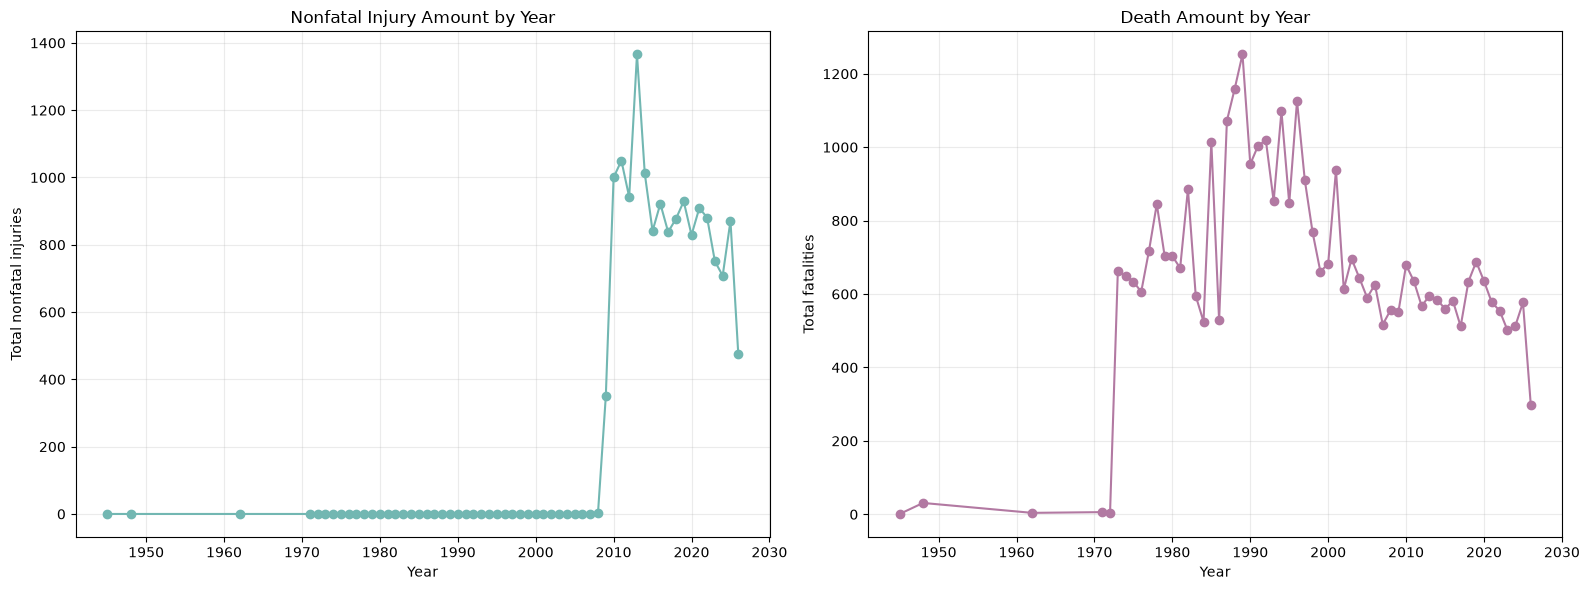

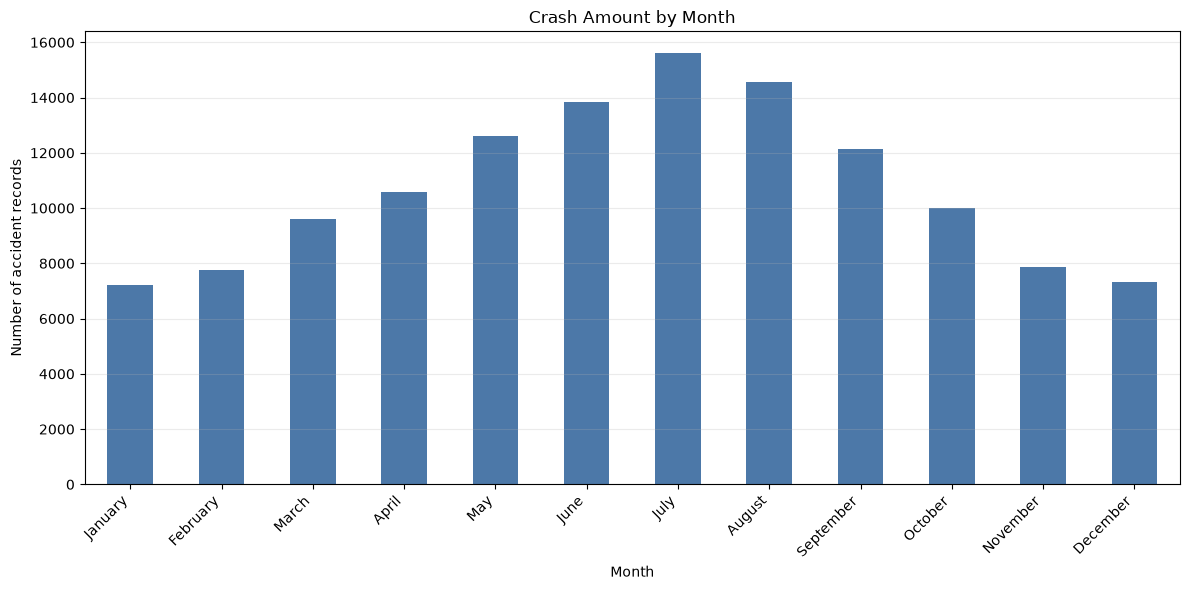

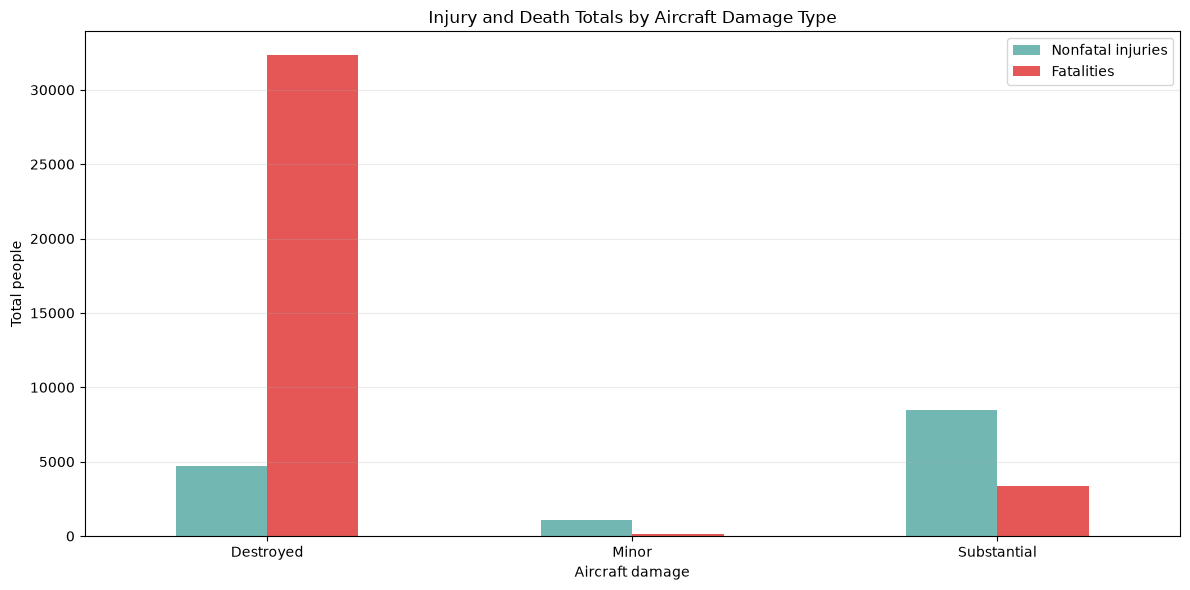

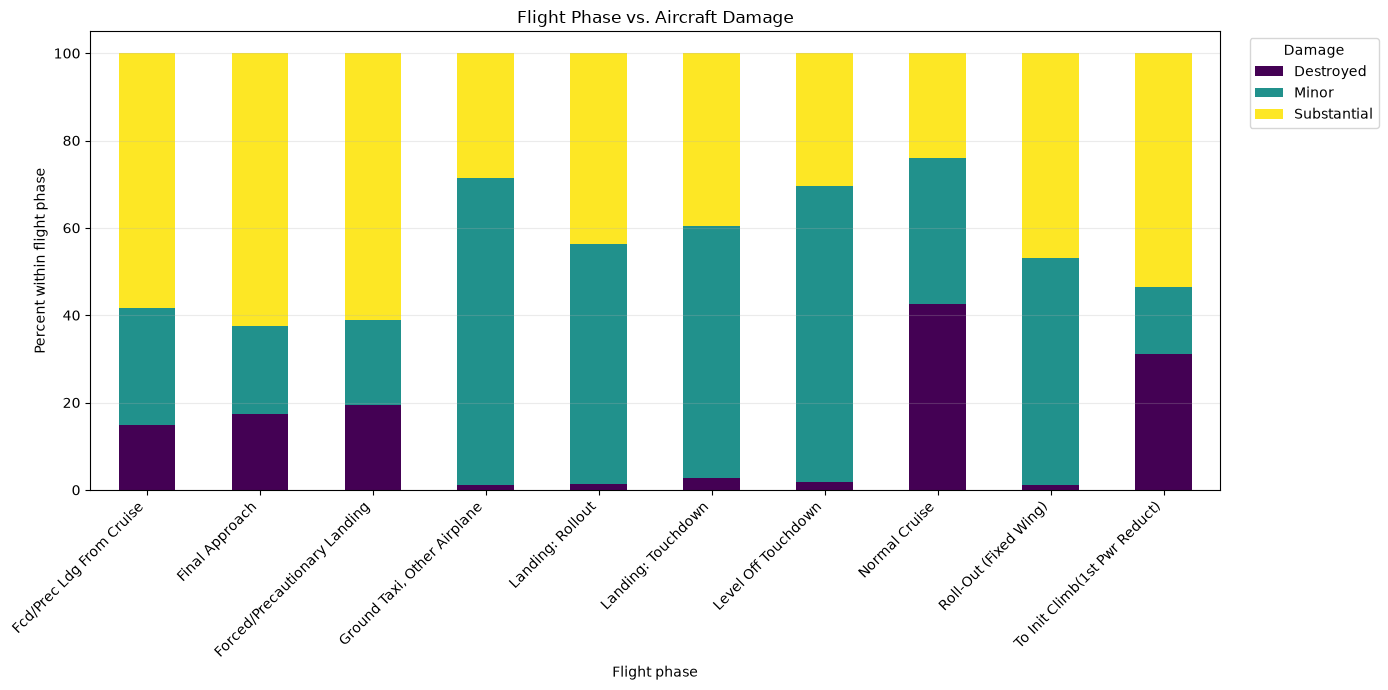

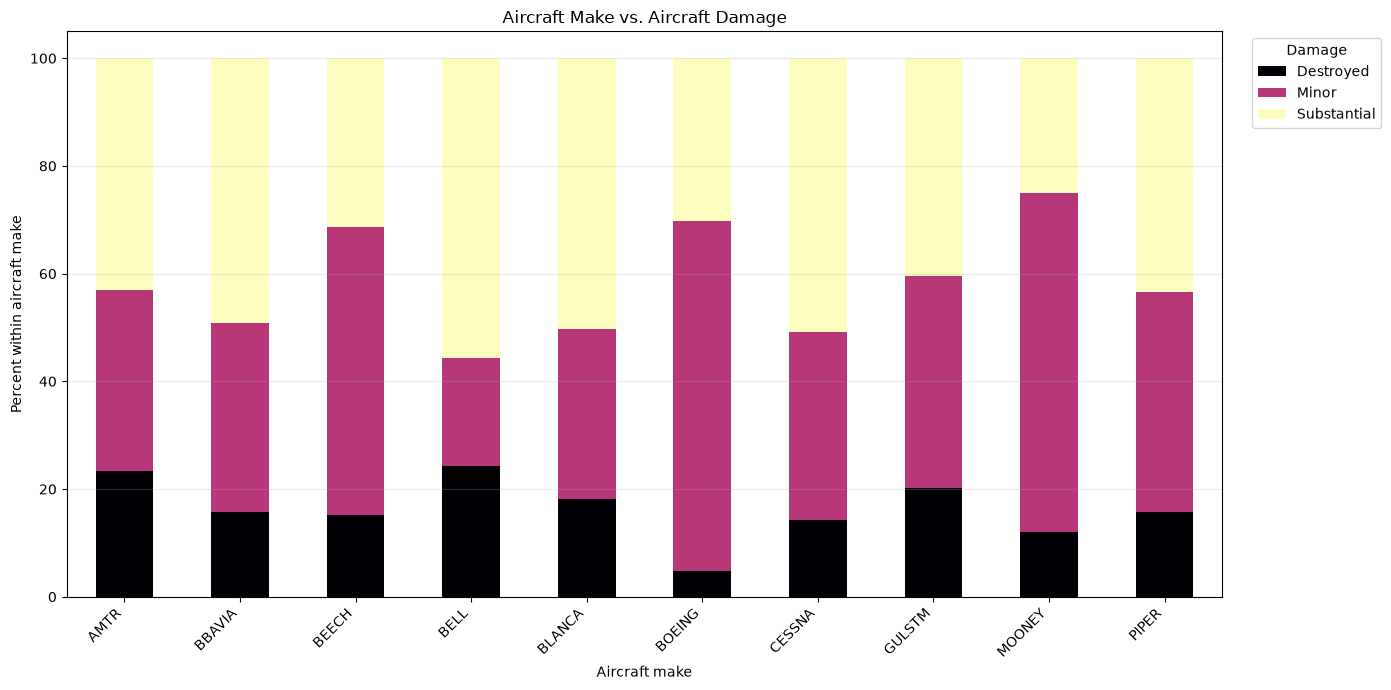

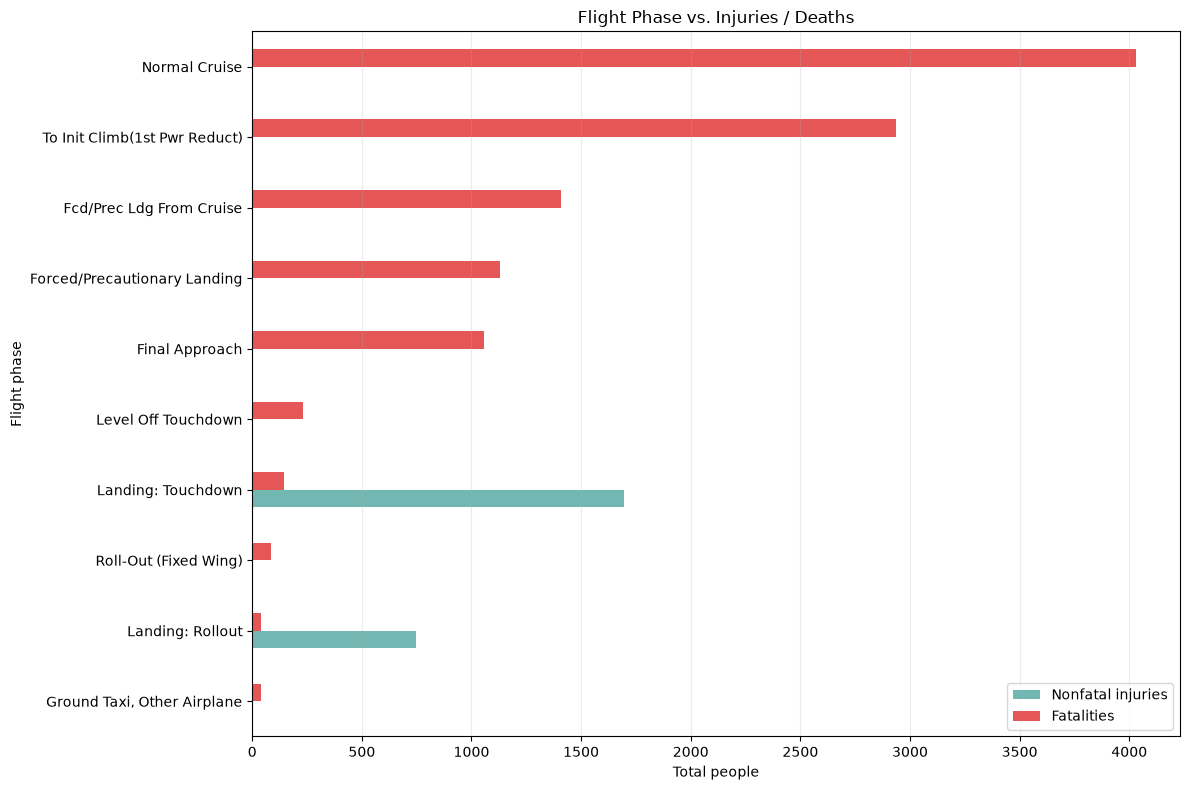

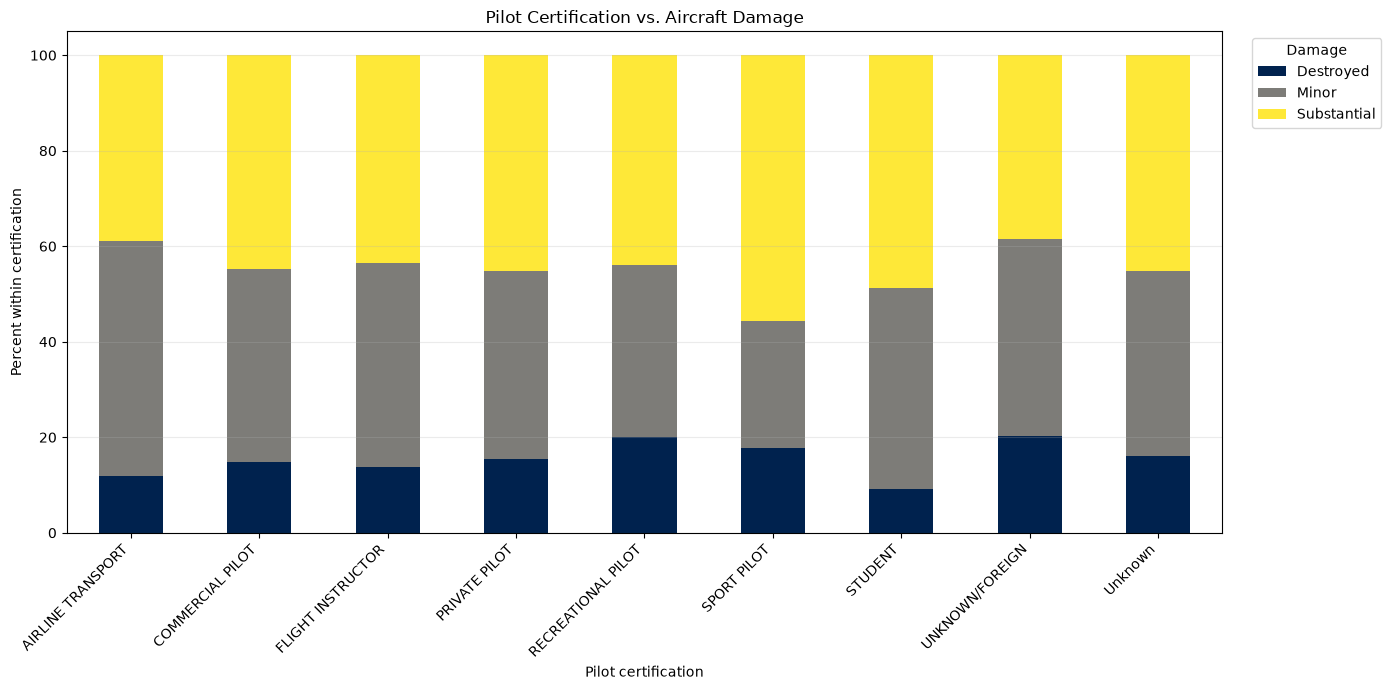

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

graph_df = df_clean.copy()
graph_df["event_year"] = graph_df["event_lcl_date"].dt.year
graph_df["event_month"] = graph_df["event_lcl_date"].dt.month
for column in [
    "flt_phase_code", "acft_make", "pic_cert_type_code",
    "acft_dmg_code", "event_type_code"
]:
    graph_df[column] = graph_df[column].fillna("Unknown")

graph_df["Fatalities"] = pd.to_numeric(
    graph_df["inj_total_invlvd_fatal_qty"], errors="coerce"
).fillna(0)
graph_df["Nonfatal injuries"] = pd.to_numeric(
    graph_df["inj_total_invlvd_non_fatal_qty"], errors="coerce"
).fillna(0)

# Injury and death totals by year
outcomes_by_year = graph_df.groupby("event_year")[
    ["Nonfatal injuries", "Fatalities"]
].sum()
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)
outcomes_by_year["Nonfatal injuries"].plot(ax=axes[0], marker="o", color="#72B7B2")
axes[0].set_title("Nonfatal Injury Amount by Year")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Total nonfatal injuries")
axes[0].grid(alpha=0.25)
outcomes_by_year["Fatalities"].plot(ax=axes[1], marker="o", color="#B279A2")
axes[1].set_title("Death Amount by Year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Total fatalities")
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Accident records by calendar month, across all years
accident_month_counts = (
    graph_df.loc[graph_df["event_type_code"] == "Accident", "event_month"]
    .value_counts()
    .reindex(range(1, 13), fill_value=0)
)
month_labels = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]
accident_month_counts.index = month_labels
accident_month_counts.plot.bar(figsize=(12, 6), color="#4C78A8")
plt.title("Crash Amount by Month")
plt.xlabel("Month")
plt.ylabel("Number of accident records")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Injury and death totals by aircraft damage type
usable_damage = graph_df[
    graph_df["acft_dmg_code"].isin(["Minor", "Substantial", "Destroyed"])
]
outcomes_by_damage = usable_damage.groupby("acft_dmg_code")[
    ["Nonfatal injuries", "Fatalities"]
].sum()
outcomes_by_damage.plot.bar(figsize=(12, 6), color=["#72B7B2", "#E45756"])
plt.title("Injury and Death Totals by Aircraft Damage Type")
plt.xlabel("Aircraft damage")
plt.ylabel("Total people")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Flight phase vs. damage
top_phases = usable_damage["flt_phase_code"].value_counts().head(10).index
damage_by_phase = pd.crosstab(
    usable_damage.loc[usable_damage["flt_phase_code"].isin(top_phases), "flt_phase_code"],
    usable_damage.loc[usable_damage["flt_phase_code"].isin(top_phases), "acft_dmg_code"],
    normalize="index",
).mul(100)
damage_by_phase.plot.bar(stacked=True, figsize=(14, 7), colormap="viridis")
plt.title("Flight Phase vs. Aircraft Damage")
plt.xlabel("Flight phase")
plt.ylabel("Percent within flight phase")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Damage", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Aircraft make vs. damage
top_makes = usable_damage["acft_make"].value_counts().head(10).index
damage_by_make = pd.crosstab(
    usable_damage.loc[usable_damage["acft_make"].isin(top_makes), "acft_make"],
    usable_damage.loc[usable_damage["acft_make"].isin(top_makes), "acft_dmg_code"],
    normalize="index",
).mul(100)
damage_by_make.plot.bar(stacked=True, figsize=(14, 7), colormap="magma")
plt.title("Aircraft Make vs. Aircraft Damage")
plt.xlabel("Aircraft make")
plt.ylabel("Percent within aircraft make")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Damage", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Flight phase vs. injuries and deaths
phase_outcomes = usable_damage[
    usable_damage["flt_phase_code"].isin(top_phases)
].groupby("flt_phase_code")[["Nonfatal injuries", "Fatalities"]].sum()
phase_outcomes.sort_values("Fatalities", ascending=True).plot.barh(
    figsize=(12, 8), color=["#72B7B2", "#E45756"]
)
plt.title("Flight Phase vs. Injuries / Deaths")
plt.xlabel("Total people")
plt.ylabel("Flight phase")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

# Pilot certification vs. damage
top_certifications = usable_damage["pic_cert_type_code"].value_counts().head(10).index
pilot_damage = usable_damage[
    usable_damage["pic_cert_type_code"].isin(top_certifications)
]
pilot_damage_table = pd.crosstab(
    pilot_damage["pic_cert_type_code"],
    pilot_damage["acft_dmg_code"],
    normalize="index",
).mul(100)
pilot_damage_table.plot.bar(stacked=True, figsize=(14, 7), colormap="cividis")
plt.title("Pilot Certification vs. Aircraft Damage")
plt.xlabel("Pilot certification")
plt.ylabel("Percent within certification")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Damage", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


# 4. Preprocessing and grouped train/test splitting

This section prepares model-ready datasets without leaking information from the test set. Repeated report numbers are kept together using a grouped 80/20 split. Categorical preprocessing is defined with scikit-learn pipelines and is fitted only on training data during model development.


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Use the Phase 1 feature policy and keep the report number only as a grouping key.
model_feature_columns = feature_columns.copy()

# Build fresh target datasets so Phase 4 can be rerun independently.
phase4_damage_df = damage_model_df[
    model_feature_columns + ['acft_dmg_code', 'rprt_nbr']
].copy()
phase4_fatality_df = fatality_model_df[
    model_feature_columns + ['fatality_class', 'rprt_nbr']
].copy()
phase4_nonfatal_df = nonfatal_model_df[
    model_feature_columns + ['nonfatal_injury_class', 'rprt_nbr']
].copy()

# Nullable integer targets must be converted to ordinary integers for scikit-learn.
phase4_fatality_df['fatality_class'] = phase4_fatality_df['fatality_class'].astype(int)
phase4_nonfatal_df['nonfatal_injury_class'] = (
    phase4_nonfatal_df['nonfatal_injury_class'].astype(int)
)

# Define a grouped 80/20 split for each target.
group_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

def make_grouped_split(dataframe, target_column):
    X = dataframe[model_feature_columns].copy()
    y = dataframe[target_column].copy()
    groups = dataframe['rprt_nbr'].copy()

    train_indices, test_indices = next(
        group_splitter.split(X, y, groups=groups)
    )

    X_train = X.iloc[train_indices].copy()
    X_test = X.iloc[test_indices].copy()
    y_train = y.iloc[train_indices].copy()
    y_test = y.iloc[test_indices].copy()
    groups_train = groups.iloc[train_indices].copy()
    groups_test = groups.iloc[test_indices].copy()

    overlap = set(groups_train).intersection(groups_test)
    if overlap:
        raise ValueError(f'Group leakage detected for {target_column}')

    return {
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train,
        'y_test': y_test,
        'groups_train': groups_train,
        'groups_test': groups_test
    }

phase4_splits = {
    'damage': make_grouped_split(phase4_damage_df, 'acft_dmg_code'),
    'fatality': make_grouped_split(phase4_fatality_df, 'fatality_class'),
    'nonfatal_injury': make_grouped_split(
        phase4_nonfatal_df,
        'nonfatal_injury_class'
    )
}

print("Grouped Report-Level Split Summary:")
for target_name, split in phase4_splits.items():
    print(f"\n{target_name.replace('_', ' ').title()} Target:")
    print("Training rows:", len(split['X_train']))
    print("Testing rows:", len(split['X_test']))
    print("Training reports:", split['groups_train'].nunique())
    print("Testing reports:", split['groups_test'].nunique())
    print(
        "Overlapping reports:",
        len(set(split['groups_train']).intersection(split['groups_test']))
    )
    print("Training target distribution:")
    display(split['y_train'].value_counts(normalize=True).mul(100).round(2).rename('Percent').to_frame())
    print("Testing target distribution:")
    display(split['y_test'].value_counts(normalize=True).mul(100).round(2).rename('Percent').to_frame())

# Define reusable preprocessing for categorical features.
# It is intentionally not fitted here; model pipelines will fit it on training data only.
categorical_preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            Pipeline([
                ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
                ('onehot', OneHotEncoder(
                    handle_unknown='ignore',
                    min_frequency=5,
                    sparse_output=True
                ))
            ]),
            model_feature_columns
        )
    ],
    remainder='drop'
)

scaled_categorical_preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            Pipeline([
                ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
                ('onehot', OneHotEncoder(
                    handle_unknown='ignore',
                    min_frequency=5,
                    sparse_output=True
                )),
                ('scale', StandardScaler(with_mean=False))
            ]),
            model_feature_columns
        )
    ],
    remainder='drop'
)

# Fit only on the damage training data as a leakage check.
damage_preprocessor_check = scaled_categorical_preprocessor.fit(
    phase4_splits['damage']['X_train']
)
damage_train_transformed = damage_preprocessor_check.transform(
    phase4_splits['damage']['X_train']
)
damage_test_transformed = damage_preprocessor_check.transform(
    phase4_splits['damage']['X_test']
)

print("\nLeakage-Safe Transformation Check:")
print("Transformed damage training shape:", damage_train_transformed.shape)
print("Transformed damage testing shape:", damage_test_transformed.shape)
print("Preprocessor fitted using training data only: True")


Grouped Report-Level Split Summary:

Damage Target:
Training rows: 164765
Testing rows: 41340
Training reports: 153728
Testing reports: 38432
Overlapping reports: 0
Training target distribution:


,Percent
acft_dmg_code,
Substantial,44.98
Minor,39.35
Destroyed,15.67


Testing target distribution:


,Percent
acft_dmg_code,
Substantial,45.00
Minor,39.34
Destroyed,15.66



Fatality Target:
Training rows: 193309
Testing rows: 48372
Training reports: 180088
Testing reports: 45023
Overlapping reports: 0
Training target distribution:


,Percent
fatality_class,
0,91.84
1,8.16


... (3 outputs left out)

,Percent
nonfatal_injury_class,
0,96.01
1,3.99


Testing target distribution:


,Percent
nonfatal_injury_class,
0,95.83
1,4.17



Leakage-Safe Transformation Check:
Transformed damage training shape: (164765, 3369)
Transformed damage testing shape: (41340, 3369)
Preprocessor fitted using training data only: True


# 5. Model training and comparison

The modeling workflow follows the prepared splits: first the three classifiers are tuned and fitted for each target, then their held-out performance is evaluated, robustness is checked, and the final comparison tools are demonstrated.

## 5.1 Train and tune the models

This section contains the complete machine-learning workflow: it trains the three classifiers for each outcome target, evaluates them on held-out data, compares their performance, and uses the fitted models for custom predictions. The held-out test partition remains untouched until final evaluation.

In [6]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier

# Small grouped searches keep tuning reproducible and practical for this dataset.
cv = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=42)
def majority_baseline(y_train, y_test):
    majority_class = y_train.mode().iloc[0]
    predictions = [majority_class] * len(y_test)
    return {
        'model': 'Majority baseline',
        'accuracy': accuracy_score(y_test, predictions),
        'macro_f1': f1_score(y_test, predictions, average='macro', zero_division=0),
        'best_params': {'class': majority_class}
    }

def train_target_models(target_name, split):
    y_train = split['y_train']
    y_test = split['y_test']
    groups_train = split['groups_train']
    knn_training_limit = 5000

    baseline = majority_baseline(y_train, y_test)
    model_specs = {
        'Random Forest': {
            'preprocessor': categorical_preprocessor,
            'estimator': RandomForestClassifier(
                class_weight='balanced',
                random_state=42,
                n_jobs=1
            ),
            'param_grid': {
                'model__n_estimators': [50],
                'model__max_depth': [15, 20],
                'model__min_samples_split': [10]
            }
        },
        'Logistic Regression': {
            'preprocessor': scaled_categorical_preprocessor,
            'estimator': LogisticRegression(
                class_weight='balanced',
                max_iter=500,
                solver='lbfgs',
                random_state=42
            ),
            'param_grid': {
                'model__C': [0.5, 1.0]
            }
        },
        'K-Nearest Neighbors': {
            'preprocessor': scaled_categorical_preprocessor,
            'estimator': KNeighborsClassifier(
                weights='distance',
                metric='cosine',
                n_jobs=1
            ),
            'param_grid': {
                'model__n_neighbors': [11, 15]
            }
        }
    }

    fitted_models = {}
    evaluation_rows = [baseline]
    for model_name, spec in model_specs.items():
        pipeline = Pipeline([
            ('preprocessor', clone(spec['preprocessor'])),
            ('model', spec['estimator'])
        ])
        fit_X = split['X_train']
        fit_y = y_train
        fit_groups = groups_train
        if model_name == 'K-Nearest Neighbors' and len(fit_X) > knn_training_limit:
            sample_indices = fit_X.sample(
                n=knn_training_limit,
                random_state=42
            ).index
            fit_X = fit_X.loc[sample_indices]
            fit_y = y_train.loc[sample_indices]
            fit_groups = groups_train.loc[sample_indices]
        search = GridSearchCV(
            estimator=pipeline,
            param_grid=spec['param_grid'],
            scoring='f1_macro',
            cv=cv,
            refit=True,
            n_jobs=1,
            return_train_score=False
        )
        search.fit(fit_X, fit_y, groups=fit_groups)
        predictions = search.predict(split['X_test'])
        fitted_models[model_name] = search.best_estimator_
        evaluation_rows.append({
            'model': model_name,
            'accuracy': accuracy_score(y_test, predictions),
            'macro_f1': f1_score(y_test, predictions, average='macro', zero_division=0),
            'cv_macro_f1': search.best_score_,
            'best_params': search.best_params_
        })

    return fitted_models, pd.DataFrame(evaluation_rows)

phase5_models = {}
phase5_results = {}
for target_name, split in phase4_splits.items():
    phase5_models[target_name], phase5_results[target_name] = train_target_models(
        target_name, split
    )
    print(f"\n{target_name.replace('_', ' ').title()} Target Performance:")
    display(phase5_results[target_name][['model', 'accuracy', 'macro_f1', 'cv_macro_f1']])
    print("Best Grouped-CV Parameters:")
    display(phase5_results[target_name][['model', 'best_params']])



Damage Target Performance:


,model,accuracy,macro_f1,cv_macro_f1
0,Majority baseline,0.450048,0.206912,NaN
1,Random Forest,0.791606,0.755656,0.751835
2,Logistic Regression,0.801814,0.763015,0.761514
3,K-Nearest Neighbors,0.669811,0.594957,0.597805


Best Grouped-CV Parameters:


,model,best_params
0,Majority baseline,{'class': 'Substantial'}
1,Random Forest,"{'model__max_depth': 20, 'model__min_samples_s..."
2,Logistic Regression,{'model__C': 0.5}
3,K-Nearest Neighbors,{'model__n_neighbors': 11}



Fatality Target Performance:


,model,accuracy,macro_f1,cv_macro_f1
0,Majority baseline,0.916646,0.478255,NaN
1,Random Forest,0.732903,0.599406,0.589130
2,Logistic Regression,0.823100,0.667950,0.667021
3,K-Nearest Neighbors,0.909555,0.571333,0.553841


... (2 outputs left out)


Nonfatal Injury Target Performance:


,model,accuracy,macro_f1,cv_macro_f1
0,Majority baseline,0.958261,0.489343,NaN
1,Random Forest,0.877698,0.655179,0.669944
2,Logistic Regression,0.891383,0.673010,0.665175
3,K-Nearest Neighbors,0.954871,0.536836,0.563825


Best Grouped-CV Parameters:


,model,best_params
0,Majority baseline,{'class': 0}
1,Random Forest,"{'model__max_depth': 20, 'model__min_samples_s..."
2,Logistic Regression,{'model__C': 0.5}
3,K-Nearest Neighbors,{'model__n_neighbors': 11}


## 5.2 Held-out evaluation and model interpretation

The held-out test sets are used once for the final comparisons below. Results report macro precision and recall, balanced accuracy, per-class metrics, and confusion matrices. Permutation importance and Logistic Regression coefficients are association summaries, not causal effects.

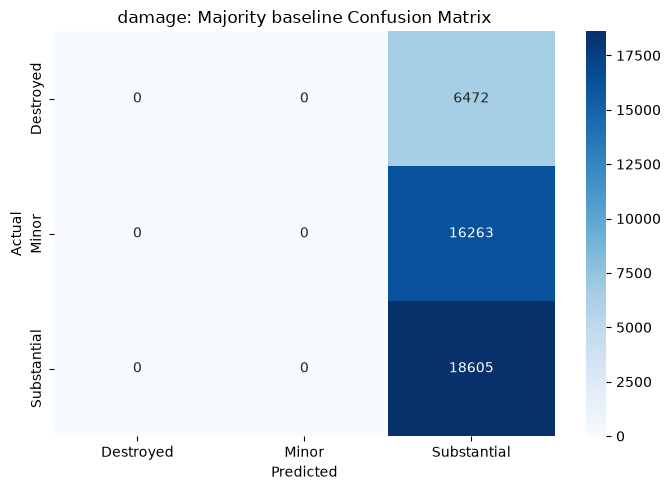

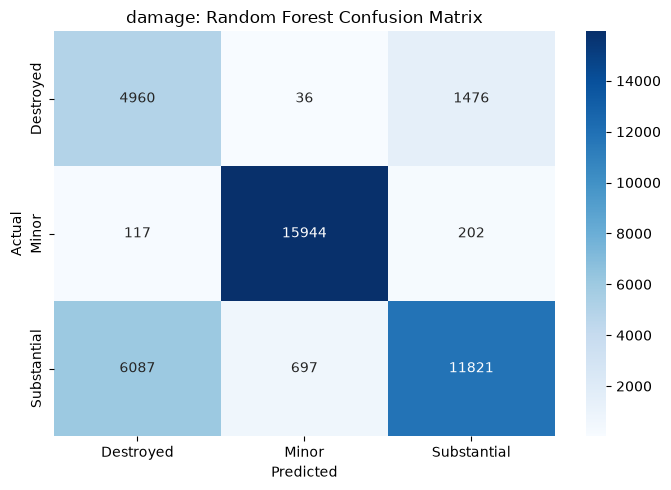

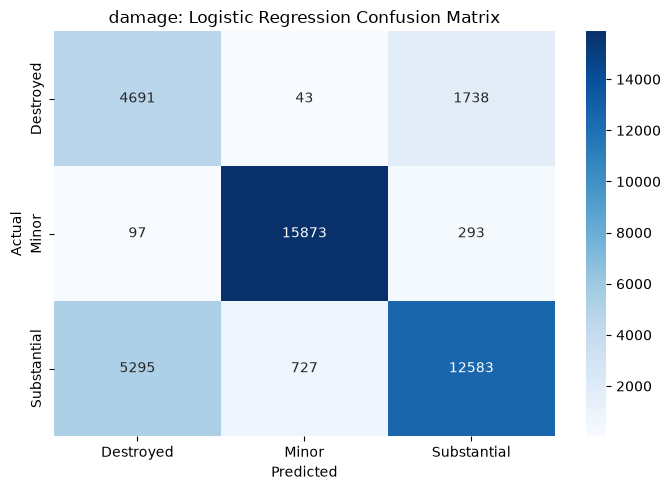

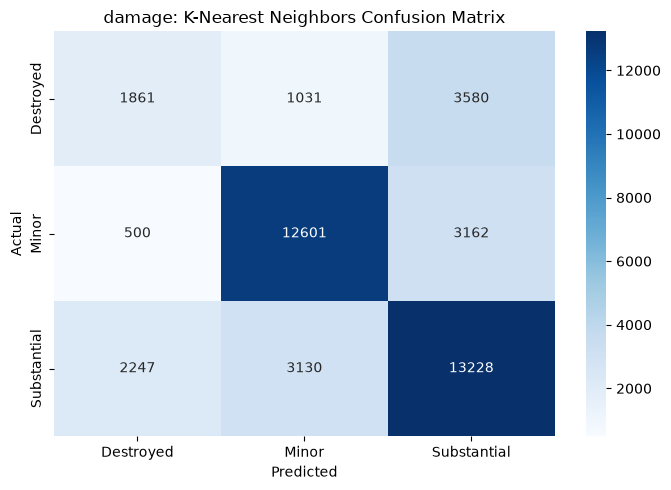


Damage Target on Held-Out Test Data:


,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1
Model,,,,,
Majority baseline,0.4500,0.3333,0.1500,0.3333,0.2069
Random Forest,0.7916,0.7940,0.7587,0.7940,0.7557
Logistic Regression,0.8018,0.7924,0.7600,0.7924,0.7630
K-Nearest Neighbors,0.6698,0.5911,0.6060,0.5911,0.5950


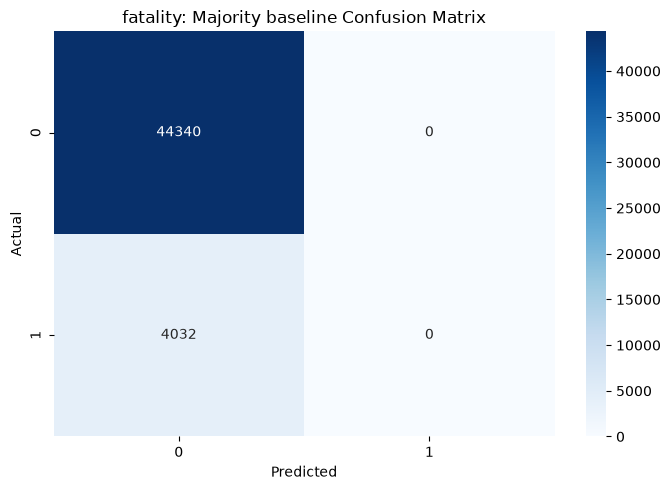

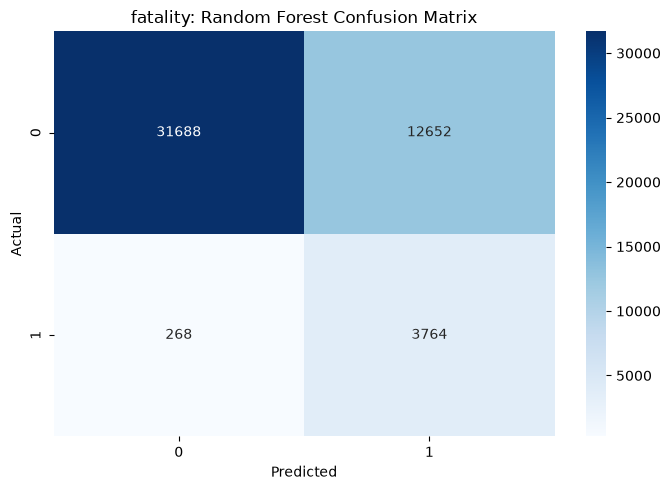

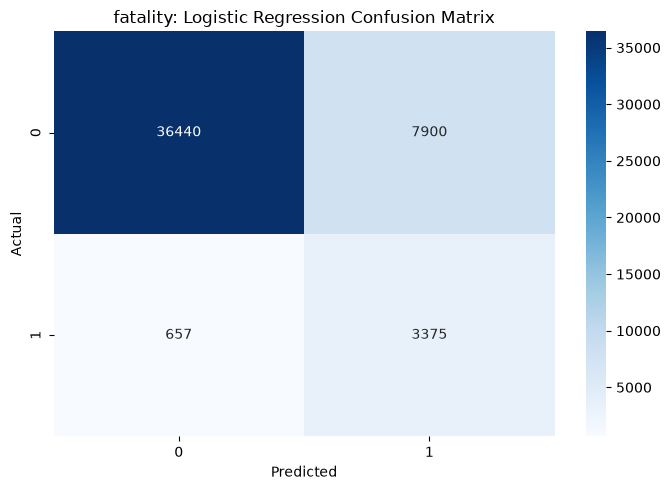

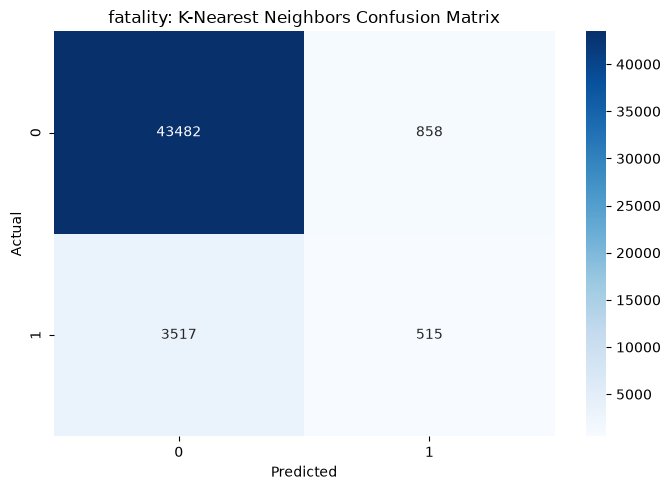


Fatality Target on Held-Out Test Data:


,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1
Model,,,,,
Majority baseline,0.9166,0.5000,0.4583,0.5000,0.4783
Random Forest,0.7329,0.8241,0.6105,0.8241,0.5994
Logistic Regression,0.8231,0.8294,0.6408,0.8294,0.6679
K-Nearest Neighbors,0.9096,0.5542,0.6501,0.5542,0.5713


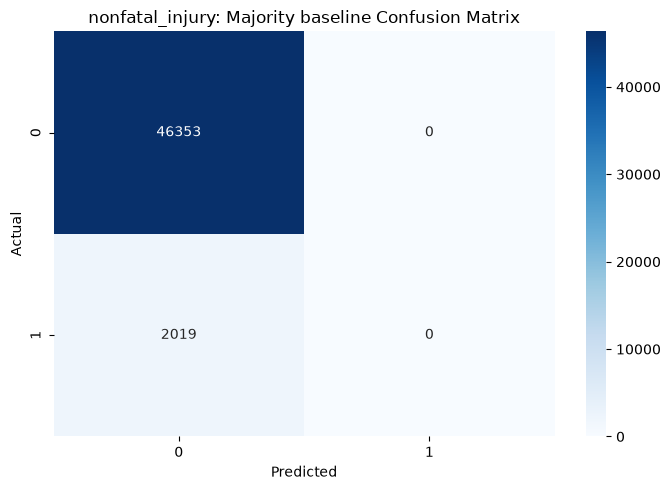

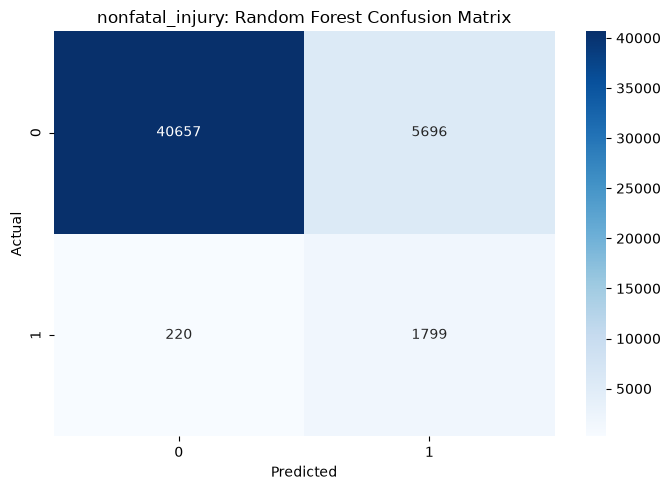

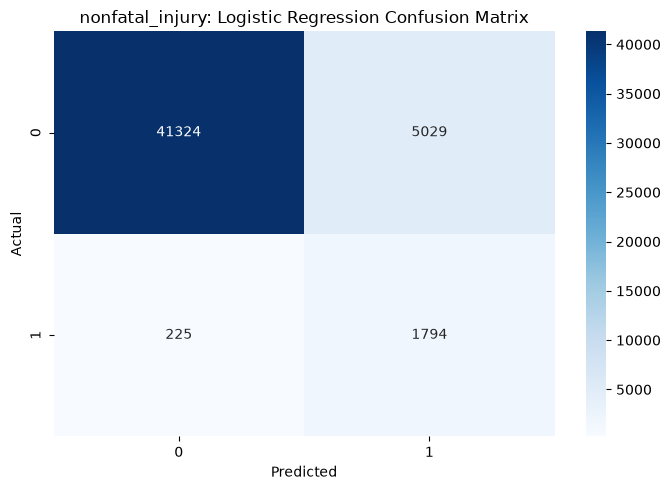

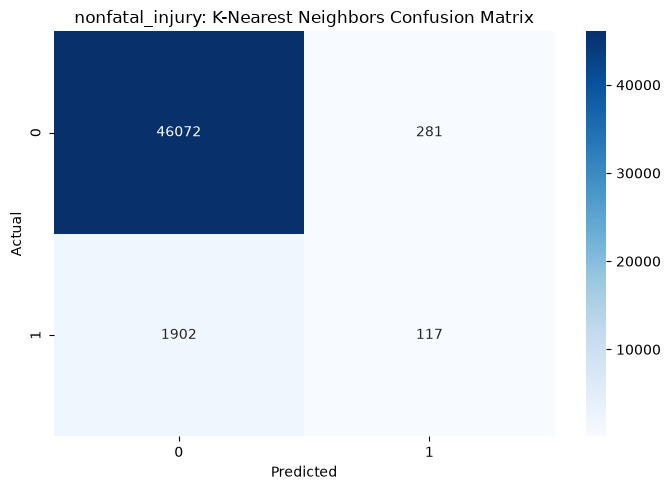


Nonfatal Injury Target on Held-Out Test Data:


,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1
Model,,,,,
Majority baseline,0.9583,0.5000,0.4791,0.5000,0.4893
Random Forest,0.8777,0.8841,0.6173,0.8841,0.6552
Logistic Regression,0.8914,0.8900,0.6288,0.8900,0.6730
K-Nearest Neighbors,0.9549,0.5259,0.6272,0.5259,0.5368



Damage Per-Class Precision, Recall, and F1:
Model: Majority baseline


,precision,recall,f1-score,support
Destroyed,0.0000,0.0000,0.0000,6472.00
Minor,0.0000,0.0000,0.0000,16263.00
Substantial,0.4500,1.0000,0.6207,18605.00
accuracy,0.4500,0.4500,0.4500,0.45
macro avg,0.1500,0.3333,0.2069,41340.00
weighted avg,0.2025,0.4500,0.2794,41340.00


Model: Random Forest


,precision,recall,f1-score,support
Destroyed,0.4443,0.7664,0.5625,6472.0000
Minor,0.9560,0.9804,0.9681,16263.0000
Substantial,0.8757,0.6354,0.7364,18605.0000
accuracy,0.7916,0.7916,0.7916,0.7916
macro avg,0.7587,0.7940,0.7557,41340.0000
weighted avg,0.8398,0.7916,0.8003,41340.0000


... (28 outputs left out)


Nonfatal Injury Random Forest Permutation Importance:


,Feature,Mean importance
2,pic_cert_type_code,0.089313
0,event_type_code,0.038652
4,acft_model,0.002714
3,acft_make,-0.003612
1,flt_phase_code,-0.006846



Nonfatal Injury Strongest Logistic Regression Coefficients:


,Encoded feature,Coefficient
1,categorical__event_type_code_Incident,-2.036246
48,categorical__flt_phase_code_Roll-Out (Fixed Wing),-1.631225
86,categorical__pic_cert_type_code_Unknown,-1.579597
11,categorical__flt_phase_code_Fcd/Prec Ldg From ...,-1.482111
30,categorical__flt_phase_code_Landing: Touchdown,1.470843
8,categorical__flt_phase_code_Cruise/Level Flight,1.369233
31,categorical__flt_phase_code_Level Off Touchdown,-1.359635
64,categorical__flt_phase_code_Takeoff: Climb Out,1.215156
158,categorical__acft_make_AMTR,-1.196029
28,categorical__flt_phase_code_Landing: Approach,1.170727


In [7]:
import numpy as np
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score
)
import seaborn as sns

phase6_evaluation = {}
phase6_per_class = {}

for target_name, split in phase4_splits.items():
    y_test = split['y_test']
    models = [('Majority baseline', None)] + list(phase5_models[target_name].items())
    rows = []
    reports = {}

    for model_name, search in models:
        if search is None:
            predictions = np.repeat(y_test.mode().iloc[0], len(y_test))
        else:
            predictions = search.predict(split['X_test'])

        rows.append({
            'Model': model_name,
            'Accuracy': accuracy_score(y_test, predictions),
            'Balanced Accuracy': balanced_accuracy_score(y_test, predictions),
            'Macro Precision': precision_score(y_test, predictions, average='macro', zero_division=0),
            'Macro Recall': recall_score(y_test, predictions, average='macro', zero_division=0),
            'Macro F1': f1_score(y_test, predictions, average='macro', zero_division=0)
        })
        reports[model_name] = pd.DataFrame(
            classification_report(y_test, predictions, output_dict=True, zero_division=0)
        ).transpose()

        labels = sorted(pd.unique(y_test).tolist())
        matrix = confusion_matrix(y_test, predictions, labels=labels)
        plt.figure(figsize=(7, 5))
        sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
                    xticklabels=labels, yticklabels=labels)
        plt.title(f'{target_name}: {model_name} Confusion Matrix')
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.tight_layout()
        plt.show()

    phase6_evaluation[target_name] = pd.DataFrame(rows).set_index('Model')
    phase6_per_class[target_name] = reports
    print(f"\n{target_name.replace('_', ' ').title()} Target on Held-Out Test Data:")
    display(phase6_evaluation[target_name].round(4))

for target_name, reports in phase6_per_class.items():
    print(f"\n{target_name.replace('_', ' ').title()} Per-Class Precision, Recall, and F1:")
    for model_name, report in reports.items():
        print(f"Model: {model_name}")
        display(report.round(4))

print('\nRandom Forest Permutation Importance and Logistic Regression Coefficients')
for target_name, split in phase4_splits.items():
    random_forest_model = phase5_models[target_name].get('Random Forest')
    if random_forest_model is not None:
        rf_importance = permutation_importance(
            random_forest_model,
            split['X_test'],
            split['y_test'],
            scoring='f1_macro',
            n_repeats=5,
            random_state=42,
            n_jobs=-1
        )
        rf_table = pd.DataFrame({
            'Feature': model_feature_columns,
            'Mean importance': rf_importance.importances_mean
        }).sort_values('Mean importance', ascending=False)
        print(f"\n{target_name.replace('_', ' ').title()} Random Forest Permutation Importance:")
        display(rf_table.head(15).round(6))

    logistic_model_pipeline = phase5_models[target_name].get('Logistic Regression')
    if logistic_model_pipeline is not None:
        logistic_model = logistic_model_pipeline.named_steps['model']
        encoded_names = logistic_model_pipeline.named_steps[
            'preprocessor'
        ].get_feature_names_out()
        coefficients = logistic_model.coef_
        if coefficients.shape[0] == 1:
            coefficient_table = pd.DataFrame({
                'Encoded feature': encoded_names,
                'Coefficient': coefficients[0]
            }).sort_values('Coefficient', key=np.abs, ascending=False)
        else:
            frames = []
            for class_index, class_label in enumerate(logistic_model.classes_):
                frames.append(pd.DataFrame({
                    'Encoded feature': encoded_names,
                    'Coefficient': coefficients[class_index],
                    'Class': class_label
                }))
            coefficient_table = pd.concat(frames, ignore_index=True)
            coefficient_table = coefficient_table.sort_values(
                'Coefficient', key=np.abs, ascending=False
            )
        print(f"\n{target_name.replace('_', ' ').title()} Strongest Logistic Regression Coefficients:")
        display(coefficient_table.head(20).round(6))


## 5.3 Sensitivity analysis

This sensitivity check compares Logistic Regression damage performance with pilot certification included versus excluded. Both variants use the same grouped split and training-only preprocessing; differences should be interpreted as robustness evidence, not causal effects.

In [8]:
print("Pilot Certification Included Versus Excluded:")
sensitivity_features = {
    'With pilot certification': model_feature_columns,
    'Without pilot certification': [
        column for column in model_feature_columns
        if column != 'pic_cert_type_code'
    ]
}

sensitivity_rows = []
damage_split = phase4_splits['damage']
for variant_name, columns in sensitivity_features.items():
    preprocessor = ColumnTransformer(
        transformers=[
            (
                'categorical',
                Pipeline([
                    ('imputer', SimpleImputer(
                        strategy='constant', fill_value='Missing'
                    )),
                    ('onehot', OneHotEncoder(
                        handle_unknown='ignore',
                        min_frequency=5,
                        sparse_output=True
                    )),
                    ('scale', StandardScaler(with_mean=False))
                ]),
                columns
            )
        ],
        remainder='drop'
    )
    model = Pipeline([
        ('preprocessor', preprocessor),
        ('model', LogisticRegression(
            C=1.0,
            class_weight='balanced',
            max_iter=500,
            solver='lbfgs',
            random_state=42
        ))
    ])
    model.fit(damage_split['X_train'][columns], damage_split['y_train'])
    predictions = model.predict(damage_split['X_test'][columns])
    sensitivity_rows.append({
        'Variant': variant_name,
        'Accuracy': accuracy_score(damage_split['y_test'], predictions),
        'Balanced Accuracy': balanced_accuracy_score(
            damage_split['y_test'], predictions
        ),
        'Macro F1': f1_score(
            damage_split['y_test'], predictions,
            average='macro', zero_division=0
        )
    })

phase6_sensitivity = pd.DataFrame(sensitivity_rows).set_index('Variant')
display(phase6_sensitivity.round(4))


Pilot Certification Included Versus Excluded:


,Accuracy,Balanced Accuracy,Macro F1
Variant,,,
With pilot certification,0.8019,0.7925,0.7631
Without pilot certification,0.8018,0.7931,0.7632


### Engine-variable sensitivity

This check adds engine make, engine model, and engine group to the damage predictors while preserving the same grouped train/test rows. It tests whether engine information materially changes the damage-classification result.

In [9]:
print("Engine Variables Included Versus Excluded:")
engine_features = [
    'eng_make_name',
    'eng_model_name',
    'eng_grp_mkmd_code'
]
damage_split = phase4_splits['damage']
engine_X_train = df_clean.loc[damage_split['X_train'].index, engine_features].copy()
engine_X_test = df_clean.loc[damage_split['X_test'].index, engine_features].copy()
engine_X_train = pd.concat(
    [damage_split['X_train'].copy(), engine_X_train], axis=1
)
engine_X_test = pd.concat(
    [damage_split['X_test'].copy(), engine_X_test], axis=1
)
engine_columns = model_feature_columns + engine_features
engine_preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            Pipeline([
                ('imputer', SimpleImputer(
                    strategy='constant', fill_value='Missing'
                )),
                ('onehot', OneHotEncoder(
                    handle_unknown='ignore',
                    min_frequency=5,
                    sparse_output=True
                )),
                ('scale', StandardScaler(with_mean=False))
            ]),
            engine_columns
        )
    ],
    remainder='drop'
)
engine_model = Pipeline([
    ('preprocessor', engine_preprocessor),
    ('model', LogisticRegression(
        C=1.0,
        class_weight='balanced',
        max_iter=500,
        solver='lbfgs',
        random_state=42
    ))
])
engine_model.fit(engine_X_train, damage_split['y_train'])
engine_predictions = engine_model.predict(engine_X_test)
phase6_engine_sensitivity = pd.DataFrame([
    phase6_sensitivity.loc['With pilot certification'].to_dict(),
    {
        'Accuracy': accuracy_score(damage_split['y_test'], engine_predictions),
        'Balanced Accuracy': balanced_accuracy_score(
            damage_split['y_test'], engine_predictions
        ),
        'Macro F1': f1_score(
            damage_split['y_test'], engine_predictions,
            average='macro', zero_division=0
        )
    }
], index=['Without engine variables', 'With engine variables'])
display(phase6_engine_sensitivity.round(4))


Engine Variables Included Versus Excluded:


,Accuracy,Balanced Accuracy,Macro F1
Without engine variables,0.8019,0.7925,0.7631
With engine variables,0.7991,0.7852,0.7587


### Damage-class and split sensitivity

These checks test two separate robustness questions:

1. Whether retaining `None` as a damage category changes damage-classification results.
2. How much a normal row-level split can inflate performance by allowing records from the same report to appear on both sides.

In [10]:
print("None Damage Class and Row-vs-Grouped Split:")
from sklearn.model_selection import train_test_split

none_damage_df = project_df[
    project_df['acft_dmg_code'].isin([
        'Minor', 'Substantial', 'Destroyed', 'None'
    ])
][model_feature_columns + ['acft_dmg_code', 'rprt_nbr']].copy()
none_damage_df[model_feature_columns] = none_damage_df[
    model_feature_columns
].fillna('Unknown')

none_rows = none_damage_df[model_feature_columns].copy()
none_labels = none_damage_df['acft_dmg_code'].copy()
none_groups = none_damage_df['rprt_nbr'].copy()
none_train_rows, none_test_rows = next(
    group_splitter.split(none_rows, none_labels, groups=none_groups)
)
none_X_train = none_rows.iloc[none_train_rows]
none_X_test = none_rows.iloc[none_test_rows]
none_y_train = none_labels.iloc[none_train_rows]
none_y_test = none_labels.iloc[none_test_rows]

four_class_model = Pipeline([
    ('preprocessor', clone(scaled_categorical_preprocessor)),
    ('model', LogisticRegression(
        C=1.0,
        class_weight='balanced',
        max_iter=500,
        solver='lbfgs',
        random_state=42
    ))
])
four_class_model.fit(none_X_train, none_y_train)
four_class_predictions = four_class_model.predict(none_X_test)

three_class_labels = damage_split['y_test']
three_class_predictions = phase5_models['damage']['Logistic Regression'].predict(
    damage_split['X_test']
)

row_split_X_train, row_split_X_test, row_split_y_train, row_split_y_test = (
    train_test_split(
        damage_model_df[model_feature_columns],
        damage_model_df['acft_dmg_code'],
        test_size=0.20,
        random_state=42,
        stratify=damage_model_df['acft_dmg_code']
    )
)
row_split_groups_train = damage_model_df.loc[
    row_split_X_train.index, 'rprt_nbr'
]
row_split_groups_test = damage_model_df.loc[
    row_split_X_test.index, 'rprt_nbr'
]
row_split_overlap = len(set(row_split_groups_train).intersection(
    row_split_groups_test
))
row_split_model = Pipeline([
    ('preprocessor', clone(scaled_categorical_preprocessor)),
    ('model', LogisticRegression(
        C=1.0,
        class_weight='balanced',
        max_iter=500,
        solver='lbfgs',
        random_state=42
    ))
])
row_split_model.fit(row_split_X_train, row_split_y_train)
row_split_predictions = row_split_model.predict(row_split_X_test)

phase6_damage_sensitivity = pd.DataFrame([
    {
        'Variant': 'Three classes, grouped reports',
        'Accuracy': accuracy_score(three_class_labels, three_class_predictions),
        'Balanced Accuracy': balanced_accuracy_score(
            three_class_labels, three_class_predictions
        ),
        'Macro F1': f1_score(
            three_class_labels, three_class_predictions,
            average='macro', zero_division=0
        ),
        'Report overlap': 0
    },
    {
        'Variant': 'Four classes including None, grouped reports',
        'Accuracy': accuracy_score(none_y_test, four_class_predictions),
        'Balanced Accuracy': balanced_accuracy_score(
            none_y_test, four_class_predictions
        ),
        'Macro F1': f1_score(
            none_y_test, four_class_predictions,
            average='macro', zero_division=0
        ),
        'Report overlap': 0
    },
    {
        'Variant': 'Three classes, ordinary rows (leakage demo)',
        'Accuracy': accuracy_score(row_split_y_test, row_split_predictions),
        'Balanced Accuracy': balanced_accuracy_score(
            row_split_y_test, row_split_predictions
        ),
        'Macro F1': f1_score(
            row_split_y_test, row_split_predictions,
            average='macro', zero_division=0
        ),
        'Report overlap': row_split_overlap
    }
]).set_index('Variant')
display(phase6_damage_sensitivity.round(4))


None Damage Class and Row-vs-Grouped Split:


,Accuracy,Balanced Accuracy,Macro F1,Report overlap
Variant,,,,
"Three classes, grouped reports",0.8018,0.7924,0.7630,0
"Four classes including None, grouped reports",0.8019,0.7925,0.7631,0
"Three classes, ordinary rows (leakage demo)",0.8051,0.7960,0.7666,3886


## 5.4 Consolidated modeling findings

This final analysis cell summarizes the strongest held-out model for each target and consolidates the completed robustness checks.

In [11]:
phase6_summary_rows = []
for target_name, evaluation in phase6_evaluation.items():
    model_evaluation = evaluation.drop(index='Majority baseline', errors='ignore')
    best_model = model_evaluation['Macro F1'].idxmax()
    phase6_summary_rows.append({
        'Target': target_name,
        'Best Model': best_model,
        'Accuracy': model_evaluation.loc[best_model, 'Accuracy'],
        'Balanced Accuracy': model_evaluation.loc[best_model, 'Balanced Accuracy'],
        'Macro F1': model_evaluation.loc[best_model, 'Macro F1']
    })

phase6_consolidated = pd.DataFrame(phase6_summary_rows).set_index('Target')
print('Strongest Held-Out Model for Each Outcome Target:')
display(phase6_consolidated.round(4))

print('\nIncluding Versus Excluding Pilot Certification:')
display(phase6_sensitivity.round(4))

print('\nIncluding Versus Excluding Engine Variables:')
display(phase6_engine_sensitivity.round(4))

print('\nDamage-Class Definition and Row-vs-Grouped Split:')
display(phase6_damage_sensitivity.round(4))

print('\nPlain-English Summary of the Strongest Results:')
for target_name, row in phase6_consolidated.iterrows():
    print(
        f"{target_name}: {row['Best Model']} had the strongest held-out macro F1 "
        f"({row['Macro F1']:.4f}). This describes association, not causation."
    )


Strongest Held-Out Model for Each Outcome Target:


,Best Model,Accuracy,Balanced Accuracy,Macro F1
Target,,,,
damage,Logistic Regression,0.8018,0.7924,0.7630
fatality,Logistic Regression,0.8231,0.8294,0.6679
nonfatal_injury,Logistic Regression,0.8914,0.8900,0.6730



Including Versus Excluding Pilot Certification:


,Accuracy,Balanced Accuracy,Macro F1
Variant,,,
With pilot certification,0.8019,0.7925,0.7631
Without pilot certification,0.8018,0.7931,0.7632



Including Versus Excluding Engine Variables:


,Accuracy,Balanced Accuracy,Macro F1
Without engine variables,0.8019,0.7925,0.7631
With engine variables,0.7991,0.7852,0.7587



Damage-Class Definition and Row-vs-Grouped Split:


,Accuracy,Balanced Accuracy,Macro F1,Report overlap
Variant,,,,
"Three classes, grouped reports",0.8018,0.7924,0.7630,0
"Four classes including None, grouped reports",0.8019,0.7925,0.7631,0
"Three classes, ordinary rows (leakage demo)",0.8051,0.7960,0.7666,3886



Plain-English Summary of the Strongest Results:
damage: Logistic Regression had the strongest held-out macro F1 (0.7630). This describes association, not causation.
fatality: Logistic Regression had the strongest held-out macro F1 (0.6679). This describes association, not causation.
nonfatal_injury: Logistic Regression had the strongest held-out macro F1 (0.6730). This describes association, not causation.


# 6. Common-threads analysis

These descriptive analyses are kept after model validation so they provide context without being confused with predictive evaluation.

## 6.1 Describe recurring aviation patterns

This section directly answers which categories occur most frequently across the cleaned historical records, and how often those categories appear with severe damage, fatalities, or nonfatal injuries.

In [ ]:
common_threads_df = df_clean.copy()
common_threads_df['fatality_present'] = (
    common_threads_df['inj_total_invlvd_fatal_qty'].gt(0)
)
common_threads_df['nonfatal_injury_present'] = (
    common_threads_df['inj_total_invlvd_non_fatal_qty'].gt(0)
)
common_threads_df['destroyed'] = (
    common_threads_df['acft_dmg_code'].eq('Destroyed')
)

def common_factor_table(column, minimum_rows=100, top_n=15):
    data = common_threads_df.copy()
    data[column] = data[column].fillna('Missing')
    summary = data.groupby(column, dropna=False).agg(
        Record_Count=('rprt_nbr', 'size'),
        Unique_Reports=('rprt_nbr', 'nunique'),
        Fatality_Record_Count=('fatality_present', 'sum'),
        Nonfatal_Injury_Record_Count=('nonfatal_injury_present', 'sum'),
        Destroyed_Record_Count=('destroyed', 'sum')
    )
    summary['Percent_of_Clean_Data'] = summary['Record_Count'] / len(common_threads_df) * 100
    summary['Fatality_Record_Rate'] = summary['Fatality_Record_Count'] / summary['Record_Count'] * 100
    summary['Nonfatal_Injury_Record_Rate'] = summary['Nonfatal_Injury_Record_Count'] / summary['Record_Count'] * 100
    summary['Destroyed_Record_Rate'] = summary['Destroyed_Record_Count'] / summary['Record_Count'] * 100
    return summary.loc[summary['Record_Count'] >= minimum_rows].sort_values('Record_Count', ascending=False).head(top_n).round(2)

print('Most Frequent Flight Phases and Their Observed Outcomes:')
phase_common_threads = common_factor_table('flt_phase_code')
display(phase_common_threads)

print('\nMost Frequent Aircraft Makes and Their Observed Outcomes:')
make_common_threads = common_factor_table('acft_make')
display(make_common_threads)

print('\nMost Frequent Aircraft Models and Their Observed Outcomes:')
model_common_threads = common_factor_table('acft_model')
display(model_common_threads)

print('\nFlight Phases with the Highest Observed Fatality-Record Rates:')
display(phase_common_threads.sort_values('Fatality_Record_Rate', ascending=False).head(15))

print('\nFlight Phases with the Highest Observed Destroyed-Record Rates:')
display(phase_common_threads.sort_values('Destroyed_Record_Rate', ascending=False).head(15))

print('\nVisualizations:')
phase_plot_data = phase_common_threads.sort_values('Record_Count', ascending=True)
phase_rate_data = phase_common_threads.sort_values('Fatality_Record_Rate', ascending=True).tail(10)
phase_destroyed_data = phase_common_threads.sort_values('Destroyed_Record_Rate', ascending=True).tail(10)

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
phase_plot_data['Record_Count'].plot.barh(ax=axes[0], color='#4C78A8')
axes[0].set_title('Most Frequent Flight Phases')
axes[0].set_xlabel('Number of records')
axes[0].set_ylabel('Flight phase')

phase_rate_data['Fatality_Record_Rate'].plot.barh(ax=axes[1], color='#E45756')
axes[1].set_title('Observed Fatality-Record Rate by Flight Phase')
axes[1].set_xlabel('Records with one or more fatalities (%)')
axes[1].set_ylabel('Flight phase')

phase_destroyed_data['Destroyed_Record_Rate'].plot.barh(ax=axes[2], color='#F58518')
axes[2].set_title('Observed Destroyed-Record Rate by Flight Phase')
axes[2].set_xlabel('Records marked Destroyed (%)')
axes[2].set_ylabel('Flight phase')

for axis in axes.flat:
    axis.grid(axis='x', alpha=0.25)
plt.suptitle('Common Threads in Historical FAA Records', fontsize=16)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
make_plot_data = make_common_threads.sort_values('Record_Count', ascending=True)
make_plot_data['Record_Count'].plot.barh(ax=axes[0], color='#72B7B2')
axes[0].set_title('Most Frequent Aircraft Makes')
axes[0].set_xlabel('Number of records')
axes[0].set_ylabel('Aircraft make')
make_common_threads.sort_values('Fatality_Record_Rate', ascending=True).tail(10)['Fatality_Record_Rate'].plot.barh(ax=axes[1], color='#B279A2')
axes[1].set_title('Observed Fatality-Record Rate for Frequent Makes')
axes[1].set_xlabel('Records with one or more fatalities (%)')
axes[1].set_ylabel('Aircraft make')
for axis in axes:
    axis.grid(axis='x', alpha=0.25)
plt.suptitle('Aircraft Makes: Frequency and Observed Outcomes', fontsize=16)
plt.tight_layout()
plt.show()

print('\nHow to Read the Frequency and Outcome-Rate Tables:')
print('Frequency is not risk: outcome rates describe records in this dataset, not crash rates, because flight exposure is unavailable.')
print('The rate charts use categories with at least 100 records; small categories can have unstable percentages.')


## 6.2 Model comparison graph

This graph compares held-out accuracy, balanced accuracy, and macro F1 for the executed models.


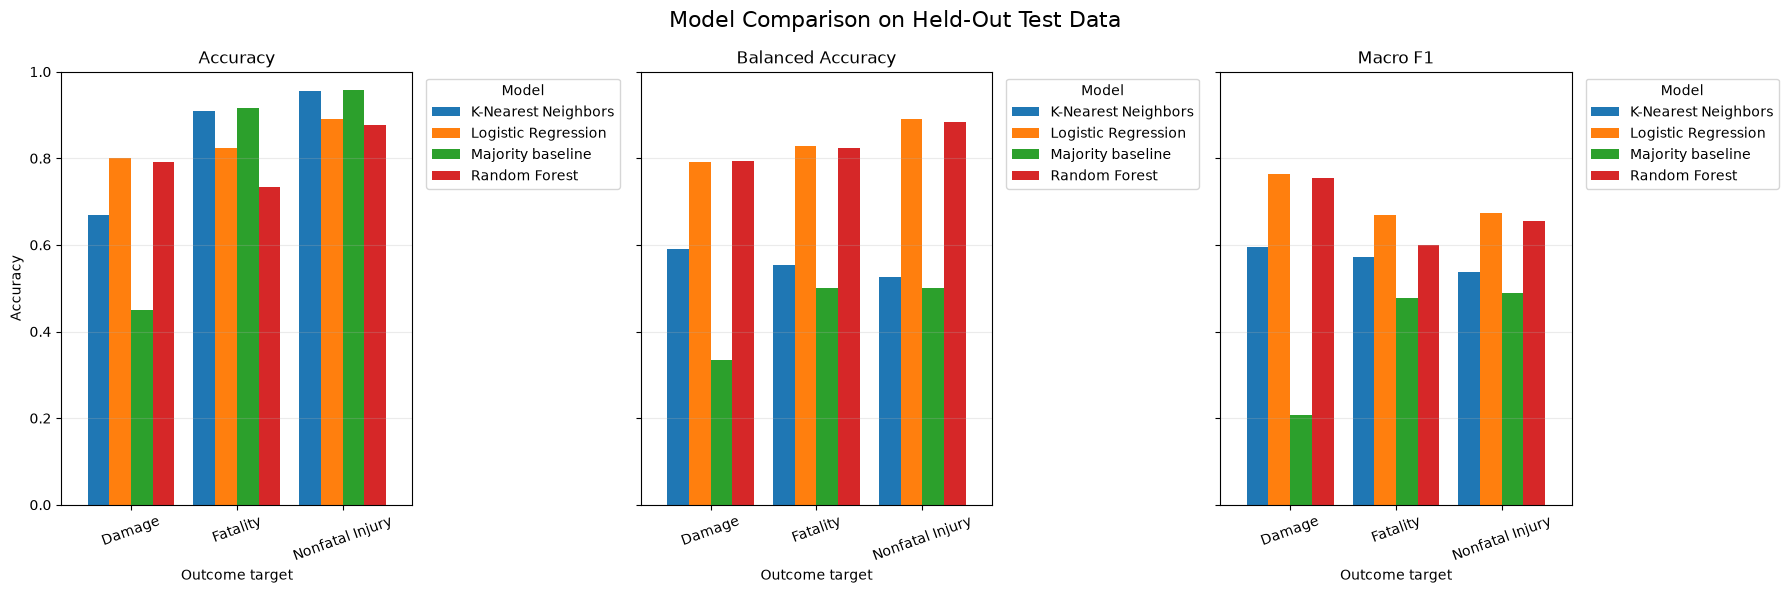

In [13]:
import matplotlib.pyplot as plt

model_comparison_rows = []
for target_name, evaluation in phase6_evaluation.items():
    for model_name, row in evaluation.iterrows():
        model_comparison_rows.append({
            "Target": target_name.replace("_", " ").title(),
            "Model": model_name,
            "Accuracy": row["Accuracy"],
            "Balanced Accuracy": row["Balanced Accuracy"],
            "Macro F1": row["Macro F1"],
        })

model_comparison = pd.DataFrame(model_comparison_rows)
metrics = ["Accuracy", "Balanced Accuracy", "Macro F1"]
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

for ax, metric in zip(axes, metrics):
    pivot = model_comparison.pivot(index="Target", columns="Model", values=metric)
    pivot.plot.bar(ax=ax, width=0.82)
    ax.set_title(metric)
    ax.set_xlabel("Outcome target")
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.suptitle("Model Comparison on Held-Out Test Data", fontsize=16)
plt.tight_layout()
plt.show()


## 6.3 Crash Outcome Prediction Comparison by Model
 
This interface compares Random Forest, Logistic Regression, and K-Nearest Neighbors predictions for damage, fatality presence, and nonfatal-injury presence. The count estimates are separate expected-value estimates, not guarantees.


In [14]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Prepare count targets from the same historical project dataset.
fatality_count_df = project_df[
    model_feature_columns
    + ["inj_total_invlvd_fatal_qty", "rprt_nbr"]
].dropna(subset=["inj_total_invlvd_fatal_qty"]).copy()
nonfatal_count_df = project_df[
    model_feature_columns
    + ["inj_total_invlvd_non_fatal_qty", "rprt_nbr"]
].dropna(subset=["inj_total_invlvd_non_fatal_qty"]).copy()

for count_df in [fatality_count_df, nonfatal_count_df]:
    count_df[model_feature_columns] = count_df[model_feature_columns].fillna("Unknown")

fatality_count_split = make_grouped_split(
    fatality_count_df, "inj_total_invlvd_fatal_qty"
)
nonfatal_count_split = make_grouped_split(
    nonfatal_count_df, "inj_total_invlvd_non_fatal_qty"
)

count_models = {}
count_splits = {
    "fatality_count": fatality_count_split,
    "nonfatal_injury_count": nonfatal_count_split,
}

for target_name, split in count_splits.items():
    fit_X = split["X_train"]
    fit_y = split["y_train"]

    if len(fit_X) > 50000:
        sample_indices = fit_X.sample(
            n=50000,
            random_state=42
        ).index
        fit_X = fit_X.loc[sample_indices]
        fit_y = fit_y.loc[sample_indices]

    count_model = Pipeline([
        ("preprocessor", clone(categorical_preprocessor)),
        ("model", RandomForestRegressor(
            n_estimators=50,
            max_depth=20,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=1,
        )),
    ])
    count_model.fit(fit_X, fit_y)
    count_models[target_name] = count_model

    count_predictions = count_model.predict(split["X_test"])
    print(
        f"{target_name.replace('_', ' ').title()} "
        f"held-out mean absolute error: "
        f"{mean_absolute_error(split['y_test'], count_predictions):.4f}"
    )


def predict_outcome(criteria):
    # criteria contains values for the five model feature columns.
    # Missing fields are set to "Unknown".
    input_row = pd.DataFrame([{
        column: criteria.get(column, "Unknown")
        for column in model_feature_columns
    }])

    model_names = list(phase5_models["damage"])
    comparison_rows = []
    for model_name in model_names:
        damage_pipeline = phase5_models["damage"][model_name]
        fatality_pipeline = phase5_models["fatality"][model_name]
        injury_pipeline = phase5_models["nonfatal_injury"][model_name]

        damage_prediction = damage_pipeline.predict(input_row)[0]
        fatality_prediction = int(fatality_pipeline.predict(input_row)[0])
        injury_prediction = int(injury_pipeline.predict(input_row)[0])

        damage_probability = damage_pipeline.predict_proba(input_row)[0]
        damage_labels = damage_pipeline.classes_

        fatality_labels = fatality_pipeline.classes_
        fatality_probability = fatality_pipeline.predict_proba(input_row)[0][
            list(fatality_labels).index(1)
        ]
        injury_labels = injury_pipeline.classes_
        injury_probability = injury_pipeline.predict_proba(input_row)[0][
            list(injury_labels).index(1)
        ]

        comparison_rows.append({
            "Model": model_name,
            "Predicted aircraft damage": damage_prediction,
            "Damage probabilities": dict(zip(
                damage_labels,
                (damage_probability * 100).round(2)
            )),
            "Fatality likely present": bool(fatality_prediction),
            "Fatality probability": round(float(fatality_probability * 100), 2),
            "Nonfatal injury likely present": bool(injury_prediction),
            "Nonfatal injury probability": round(float(injury_probability * 100), 2),
        })

    model_comparison = pd.DataFrame(comparison_rows).set_index("Model")

    estimated_fatalities = count_models["fatality_count"].predict(input_row)[0]
    estimated_injuries = count_models["nonfatal_injury_count"].predict(input_row)[0]

    return {
        "Model comparison": model_comparison,
        "Estimated fatality count": max(0.0, float(estimated_fatalities)),
        "Estimated nonfatal injury count": max(0.0, float(estimated_injuries)),
    }


example_criteria_sets = {
    "Private Cessna landing accident": {
        "event_type_code": "Accident",
        "flt_phase_code": "Landing: Touchdown",
        "pic_cert_type_code": "PRIVATE PILOT",
        "acft_make": "CESSNA",
        "acft_model": "172",
    },
    "Piper takeoff accident": {
        "event_type_code": "Accident",
        "flt_phase_code": "Takeoff",
        "pic_cert_type_code": "PRIVATE PILOT",
        "acft_make": "PIPER",
        "acft_model": "PA-28-140",
    },
    "Commercial aircraft cruise incident": {
        "event_type_code": "Incident",
        "flt_phase_code": "Cruise",
        "pic_cert_type_code": "AIRLINE TRANSPORT PILOT",
        "acft_make": "BOEING",
        "acft_model": "737",
    },
    "Helicopter maneuvering with missing model": {
        "event_type_code": "Accident",
        "flt_phase_code": "Maneuvering",
        "pic_cert_type_code": "COMMERCIAL PILOT",
        "acft_make": "BELL",
    },
}

print("Demonstration scenarios:")
print("These examples demonstrate execution and model disagreement; held-out metrics evaluate reliability.")
for scenario_name, criteria in example_criteria_sets.items():
    print(f"\n--- {scenario_name} ---")
    print("Criteria:", criteria)
    prediction_result = predict_outcome(criteria)
    display(prediction_result["Model comparison"])
    display(pd.DataFrame([{
        key: value for key, value in prediction_result.items()
        if key != "Model comparison"
    }]).T.rename(columns={0: "Estimate"}))


Fatality Count held-out mean absolute error: 0.2343
Nonfatal Injury Count held-out mean absolute error: 0.0881
Demonstration scenarios:
These examples demonstrate execution and model disagreement; held-out metrics evaluate reliability.

--- Private Cessna landing accident ---
Criteria: {'event_type_code': 'Accident', 'flt_phase_code': 'Landing: Touchdown', 'pic_cert_type_code': 'PRIVATE PILOT', 'acft_make': 'CESSNA', 'acft_model': '172'}


,Predicted aircraft damage,Damage probabilities,Fatality likely present,Fatality probability,Nonfatal injury likely present,Nonfatal injury probability
Model,,,,,,
Random Forest,Substantial,"{'Destroyed': 31.74, 'Minor': 19.61, 'Substant...",False,43.17,True,70.22
Logistic Regression,Substantial,"{'Destroyed': 13.68, 'Minor': 0.97, 'Substanti...",False,14.12,True,78.27
K-Nearest Neighbors,Substantial,"{'Destroyed': 8.68, 'Minor': 8.13, 'Substantia...",False,25.61,False,0.00


,Estimate
Estimated fatality count,0.085526
Estimated nonfatal injury count,0.286468



--- Piper takeoff accident ---
Criteria: {'event_type_code': 'Accident', 'flt_phase_code': 'Takeoff', 'pic_cert_type_code': 'PRIVATE PILOT', 'acft_make': 'PIPER', 'acft_model': 'PA-28-140'}


,Predicted aircraft damage,Damage probabilities,Fatality likely present,Fatality probability,Nonfatal injury likely present,Nonfatal injury probability
Model,,,,,,
Random Forest,Destroyed,"{'Destroyed': 42.28, 'Minor': 17.88, 'Substant...",True,60.79,True,73.79
Logistic Regression,Destroyed,"{'Destroyed': 55.61, 'Minor': 2.1, 'Substantia...",True,57.09,False,0.00
K-Nearest Neighbors,Destroyed,"{'Destroyed': 38.14, 'Minor': 35.57, 'Substant...",False,0.00,False,0.00


,Estimate
Estimated fatality count,0.100419
Estimated nonfatal injury count,0.528184


... (2 outputs left out)

,Estimate
Estimated fatality count,0.000746
Estimated nonfatal injury count,0.049112



--- Helicopter maneuvering with missing model ---
Criteria: {'event_type_code': 'Accident', 'flt_phase_code': 'Maneuvering', 'pic_cert_type_code': 'COMMERCIAL PILOT', 'acft_make': 'BELL'}


,Predicted aircraft damage,Damage probabilities,Fatality likely present,Fatality probability,Nonfatal injury likely present,Nonfatal injury probability
Model,,,,,,
Random Forest,Destroyed,"{'Destroyed': 43.79, 'Minor': 14.29, 'Substant...",True,57.72,True,72.67
Logistic Regression,Substantial,"{'Destroyed': 32.51, 'Minor': 0.85, 'Substanti...",True,63.14,False,4.40
K-Nearest Neighbors,Minor,"{'Destroyed': 0.0, 'Minor': 56.66, 'Substantia...",False,27.71,False,0.00


,Estimate
Estimated fatality count,0.085526
Estimated nonfatal injury count,0.379223
